# Ablação do procedimento de seleção

Este notebook mede o **próprio procedimento** da AutoHybTS (§30.5 da especificação): quatro maneiras de escolher o modelo final, com **o mesmo orçamento de busca** e **os mesmos testes externos**.

| Procedimento | O que faz |
|---|---|
| `lowest_error` | a finalista de menor erro em `V_select`, sem limiares |
| `incremental` | a cadeia incremental guardada (ganho ≥ 1%, vitórias ≥ 60%, variabilidade), todas as famílias |
| `incremental_simple` | a mesma cadeia, só estruturas com até 2 modelos (individual e híbrido aditivo) |
| `guarded_nested` | como `incremental`, mas se a CV aninhada disser que o procedimento não supera a melhor base, fica a base |

As séries são sintéticas e diárias, com previsibilidade do resíduo em três níveis: AR(0) (nada a corrigir), AR(0,5) e AR(0,8). Cada série guarda os últimos 14 pontos como teste externo selado.

> O teste externo serve **só para relatar**. Não escolha o procedimento "vencedor" com ele: isso repetiria o erro que a ablação quer medir.

Este notebook é pesado (≈25 min) e é versionado **com as saídas**.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts.benchmarks import PROCEDURES, ablation_report, run_ablation, synthetic_cases

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Configuração

In [ ]:
N_SERIES = 4
SEEDS = (0, 1, 2)
BUDGET = "smoke"

cases = list(synthetic_cases(N_SERIES))
pd.DataFrame(
    {
        "series_id": [c.series_id for c in cases],
        "pontos": [len(c.values) for c in cases],
        "horizonte": [c.horizon for c in cases],
        "teste_externo": [c.test_size for c in cases],
    }
)

,series_id,pontos,horizonte,teste_externo
0,syn0-phi0.0,400,14,14
1,syn1-phi0.5,400,14,14
2,syn2-phi0.8,400,14,14
3,syn3-phi0.0,400,14,14
4,syn4-phi0.5,400,14,14
5,syn5-phi0.8,400,14,14
6,syn6-phi0.0,400,14,14
7,syn7-phi0.5,400,14,14
8,syn8-phi0.8,400,14,14
9,syn9-phi0.0,400,14,14


## 2. Execução

Para cada série e semente: uma busca com todas as famílias (serve a `lowest_error`, `incremental` e `guarded_nested`), uma busca restrita (`incremental_simple`) e a CV aninhada (`guarded_nested`). Cada candidata é avaliada **uma única vez** no teste externo.

In [3]:
started = time.perf_counter()
table = run_ablation(cases, seeds=SEEDS, budget=BUDGET)
print(f"{len(table)} linhas em {(time.perf_counter() - started) / 60:.1f} min")
table.head(8)

144 linhas em 24.5 min


,series_id,seed,procedure,champion,is_hybrid,test_score,best_base_test,gain_vs_base,validation_score,gap,coverage,seconds,candidates
0,syn0-phi0.0,0,lowest_error,ma(mlp-linear),True,0.821833,1.092749,0.247922,0.933019,-0.111186,1.0,47.034913,10
1,syn0-phi0.0,0,incremental,seasonal_naive,False,1.038440,1.092749,0.049700,0.978955,0.059485,1.0,47.034913,10
2,syn0-phi0.0,0,incremental_simple,seasonal_naive,False,1.038440,1.092749,0.049700,0.978955,0.059485,1.0,7.126175,9
3,syn0-phi0.0,0,guarded_nested,knn,False,1.092749,1.092749,0.000000,0.969342,0.123407,1.0,60.191101,10
4,syn0-phi0.0,1,lowest_error,knn,False,1.092749,1.092749,0.000000,0.969342,0.123407,1.0,28.327997,10
5,syn0-phi0.0,1,incremental,knn,False,1.092749,1.092749,0.000000,0.969342,0.123407,1.0,28.327997,10
6,syn0-phi0.0,1,incremental_simple,knn,False,1.092749,1.092749,0.000000,0.969342,0.123407,1.0,9.029600,9
7,syn0-phi0.0,1,guarded_nested,knn,False,1.092749,1.092749,0.000000,0.969342,0.123407,1.0,39.698757,10


## 3. Resumo por procedimento

* `median_gain_vs_base`: ganho mediano no teste contra a melhor base individual (positivo = melhor).
* `hybrid_share`: fração de casos em que um híbrido foi escolhido.
* `beats_base_share`: fração de casos em que o escolhido bateu a melhor base no teste.
* `mean_gap`: erro no teste menos erro em `V_select` (positivo = a validação foi otimista).
* `mean_rank`: posto médio no teste entre os 4 procedimentos (menor = melhor).
* `seed_std_of_median_gain`: quanto o ganho mediano varia entre sementes.

In [4]:
report = ablation_report(table)
report.round(4)

,median_gain_vs_base,hybrid_share,beats_base_share,mean_gap,mean_rank,coverage,mean_seconds,candidates,seed_std_of_median_gain
procedure,,,,,,,,,
lowest_error,0.0,0.5278,0.4167,0.0329,2.1250,1.0,27.2612,10.0,0.0087
incremental,0.0,0.2500,0.2222,0.0507,2.5694,1.0,27.2612,10.0,0.0000
incremental_simple,0.0,0.1111,0.2500,0.0454,2.5417,1.0,4.8361,9.0,0.0000
guarded_nested,0.0,0.0278,0.0556,0.0777,2.7639,1.0,35.7119,10.0,0.0000


## 4. Por nível de previsibilidade do resíduo

Quando o resíduo é ruído branco (AR(0)), um híbrido não tem o que aprender: o bom procedimento deveria ficar com a base. Com AR(0,8), há o que corrigir.

In [5]:
table["phi"] = table["series_id"].str.extract(r"phi([0-9.]+)")[0].astype(float)
by_phi = table.pivot_table(
    index="phi",
    columns="procedure",
    values=["gain_vs_base", "is_hybrid"],
    aggfunc={"gain_vs_base": "median", "is_hybrid": "mean"},
)
by_phi.round(3)

gain_vs_base                                                  is_hybrid                                            
procedure guarded_nested incremental incremental_simple lowest_error guarded_nested incremental incremental_simple lowest_error
phi                                                                                                                            
0.0                  0.0         0.0                0.0        0.000          0.083       0.250              0.167        0.583
0.5                  0.0         0.0                0.0        0.000          0.000       0.333              0.000        0.333
0.8                  0.0         0.0                0.0        0.092          0.000       0.167              0.167        0.667

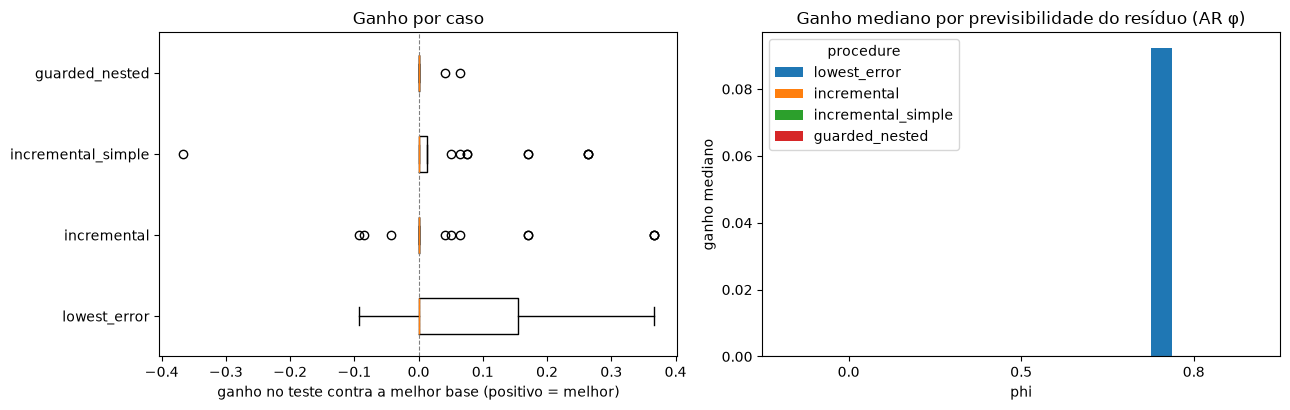

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
order = list(PROCEDURES)
axes[0].boxplot(
    [table.loc[table["procedure"] == p, "gain_vs_base"] for p in order],
    orientation="horizontal",
    tick_labels=order,
)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("ganho no teste contra a melhor base (positivo = melhor)")
axes[0].set_title("Ganho por caso")
gain_phi = table.pivot_table(
    index="phi", columns="procedure", values="gain_vs_base", aggfunc="median"
)
gain_phi[order].plot(kind="bar", ax=axes[1], rot=0)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("ganho mediano")
axes[1].set_title("Ganho mediano por previsibilidade do resíduo (AR φ)")
fig.tight_layout()

## 5. Otimismo da validação

Lacuna = erro no teste − erro em `V_select`. Um procedimento que escolhe pelo menor erro tende a pegar a candidata que teve sorte na validação; a lacuna mostra quanto disso aparece no teste.

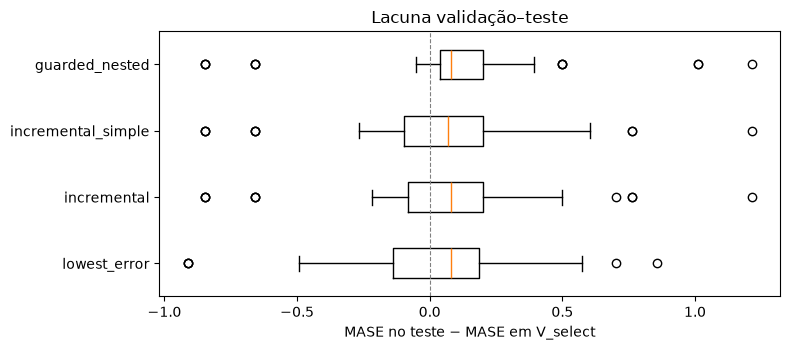

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot(
    [table.loc[table["procedure"] == p, "gap"] for p in order],
    orientation="horizontal",
    tick_labels=order,
)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("MASE no teste − MASE em V_select")
ax.set_title("Lacuna validação–teste")
fig.tight_layout()

## 6. Custo

In [8]:
report[["mean_seconds", "candidates"]].round(1)

,mean_seconds,candidates
procedure,,
lowest_error,27.3,10.0
incremental,27.3,10.0
incremental_simple,4.8,9.0
guarded_nested,35.7,10.0


## 7. Estruturas escolhidas

In [9]:
table.groupby("procedure")["champion"].value_counts().unstack(fill_value=0).T

procedure,guarded_nested,incremental,incremental_simple,lowest_error
champion,,,,
"comb(linear,seasonal_naive)",0,0,0,1
knn,6,2,2,1
linear,23,18,22,13
linear-linear,0,2,4,0
ma(knn-linear),0,0,0,3
ma(linear-linear),1,4,0,11
ma(mlp-linear),0,2,0,2
mlp,3,3,3,3
mlp-linear,0,1,0,2


## 8. Leitura dos resultados

Nesta execução (12 séries × 3 sementes, orçamento `smoke`):

* **`lowest_error`** escolhe híbrido em ~53% dos casos e tem o melhor posto médio (2,13), mas faz isso também quando o resíduo é ruído branco (AR(0): ~58% de híbridos), onde não há o que aprender. É o procedimento que mais se adapta à validação.
* **`incremental`** escolhe híbrido em 25% dos casos; **`incremental_simple`** em 11%, com o menor custo (~5 s por caso).
* **`guarded_nested`** quase nunca sai da base (3%) e só a bateu em 6% dos casos: a CV aninhada, com 2 dobras externas e orçamento `smoke`, raramente confirma o híbrido. É o mais conservador e o mais caro.
* O **ganho mediano** contra a melhor base é 0 em todos: na maioria dos casos o escolhido é a própria base ou empata com ela; as diferenças estão nas caudas (boxplot da seção 4).
* A **lacuna validação–teste** é positiva em todos (a validação foi otimista).

Limites desta ablação: séries sintéticas, orçamento pequeno, 2 dobras externas na CV aninhada e um único horizonte. O orçamento `smoke` tem limite de 60 s por busca: numa máquina ocupada, buscas podem parar pelo relógio e mudar os números. Para conclusões, rode com mais séries (ou o M4: `benchmark_cases("m4", "daily", 20)`), mais sementes e um orçamento maior, e não escolha o procedimento pelo teste externo.